In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

In [94]:
dataset = pd.read_csv("dataset/insurance.csv")

In [95]:
# first 5 rows of dataframe
dataset.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [96]:
# last 5 rows of dataframe
dataset.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [97]:
# number of rows and columns
dataset.shape

(1338, 7)

In [98]:
# some info about dataset
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [99]:
# checking for missing values
dataset.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [100]:
# statistical measure of dataset
dataset.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


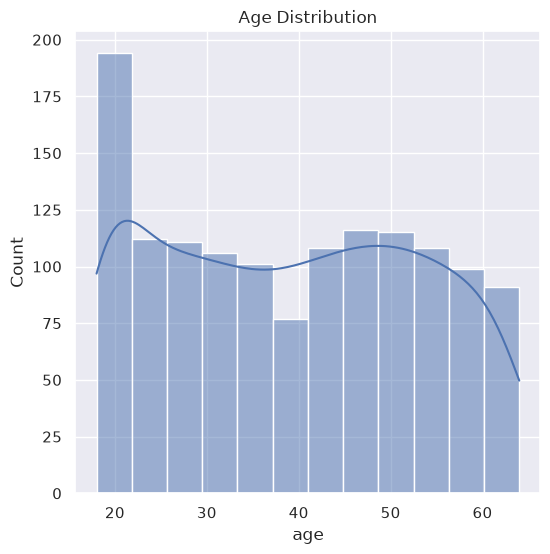

In [101]:
# distribution of age
sns.set()
plt.figure(
    figsize = (6, 6)
)
sns.histplot(
    data=dataset,
    x="age",
    kde=True
)
plt.title("Age Distribution")
plt.show()

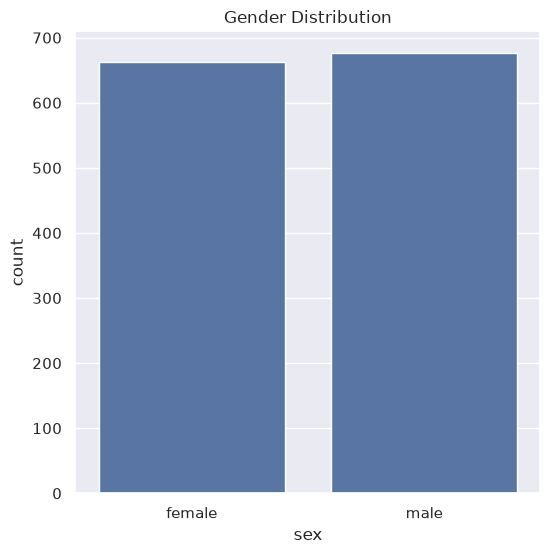

sex
male      676
female    662
Name: count, dtype: int64

In [102]:
# distribution of gender
plt.figure(
    figsize = (6, 6)
)
sns.countplot(
    x = "sex",
    data = dataset
)
plt.title("Gender Distribution")
plt.show()
dataset["sex"].value_counts()

<Figure size 600x600 with 0 Axes>

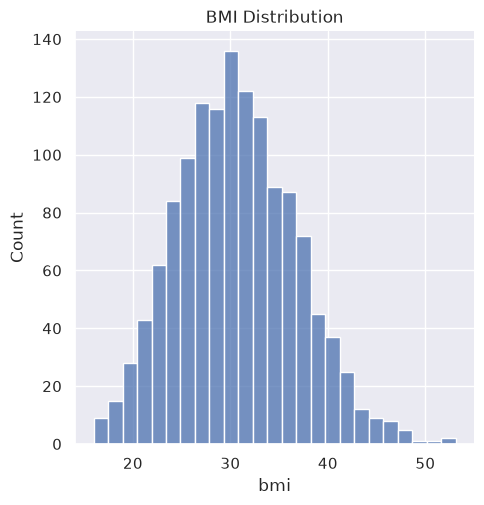

In [103]:
# BMI Distribution
plt.figure(
    figsize = (6, 6)
)
sns.displot(
    dataset["bmi"]
)
plt.title("BMI Distribution")
plt.show()

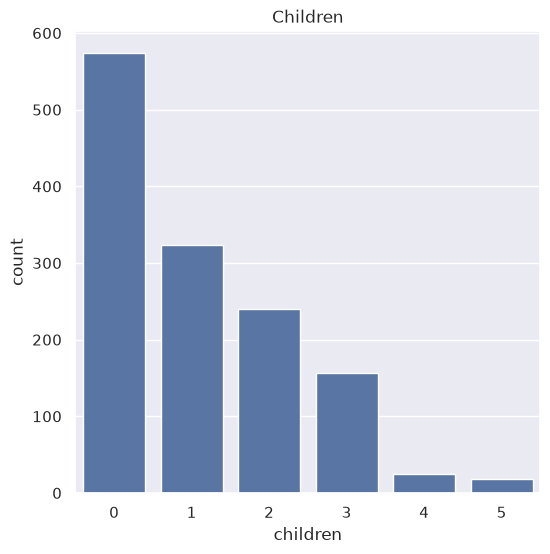

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

In [104]:
# Children Distribution
plt.figure(
    figsize = (6, 6)
)
sns.countplot(
    x = "children",
    data = dataset
)
plt.title("Children")
plt.show()
dataset["children"].value_counts()

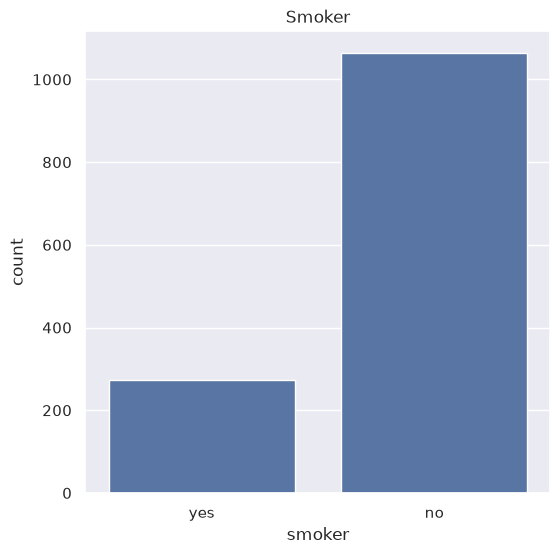

smoker
no     1064
yes     274
Name: count, dtype: int64

In [105]:
# Smoker Distribution
plt.figure(
    figsize = (6, 6)
)
sns.countplot(
    x = "smoker",
    data = dataset
)
plt.title("Smoker")
plt.show()
dataset["smoker"].value_counts()

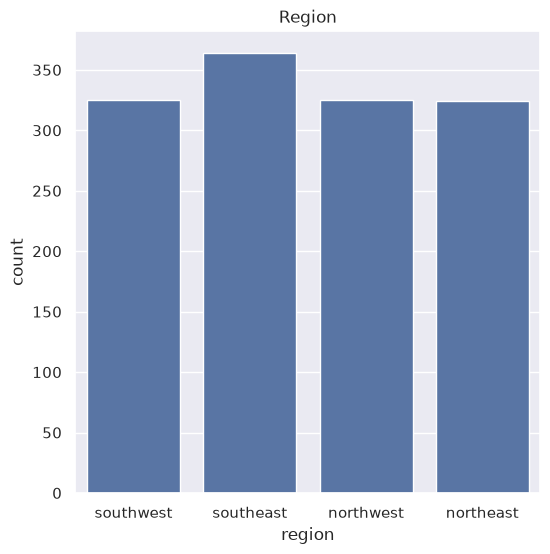

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [106]:
# Region Distribution
plt.figure(
    figsize = (6, 6)
)
sns.countplot(
    x = "region",
    data = dataset
)
plt.title("Region")
plt.show()
dataset["region"].value_counts()

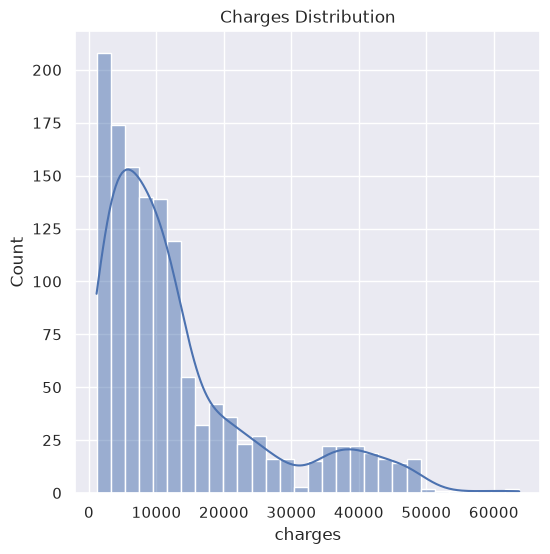

In [107]:
# Distribution of charges values
plt.figure(
    figsize = (6, 6)
)
sns.histplot(
    data=dataset,
    x="charges",
    kde=True
)
plt.title("Charges Distribution")
plt.show()

In [108]:
# Encoding sex column
dataset.replace(
    {
        "sex": {
            "male": 0,
            "female": 1
        }
    },
    inplace = True
)

# Encoding smoker column
dataset.replace(
    {
        "smoker": {
            "yes": 0,
            "no": 1
        }
    },
    inplace = True
)

# Encoding region column
dataset.replace(
    {
        "region":{
            "southeast": 0,
            "southwest": 1,
            "northeast": 2,
            "northwest": 3
        }
    },
    inplace = True
)

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,0,1,16884.92400
1,18,0,33.770,1,1,0,1725.55230
2,28,0,33.000,3,1,0,4449.46200
3,33,0,22.705,0,1,3,21984.47061
4,32,0,28.880,0,1,3,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,1,3,10600.54830
1334,18,1,31.920,0,1,2,2205.98080
1335,18,1,36.850,0,1,0,1629.83350
1336,21,1,25.800,0,1,1,2007.94500


In [113]:
X = dataset.drop(
    columns = "charges",
    axis = 0
)
Y = dataset["charges"]

In [114]:
print(X)

      age sex     bmi  children smoker region
0      19   1  27.900         0      0      1
1      18   0  33.770         1      1      0
2      28   0  33.000         3      1      0
3      33   0  22.705         0      1      3
4      32   0  28.880         0      1      3
...   ...  ..     ...       ...    ...    ...
1333   50   0  30.970         3      1      3
1334   18   1  31.920         0      1      2
1335   18   1  36.850         0      1      0
1336   21   1  25.800         0      1      1
1337   61   1  29.070         0      0      3

[1338 rows x 6 columns]


In [115]:
print(Y)

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1338, dtype: float64


In [116]:
# Splitting dataset
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size = 0.2,
    random_state = 2
)

In [117]:
print(X.shape, X_train.shape, X_test.shape)
print(Y.shape, Y_train.shape, Y_test.shape)

(1338, 6) (1070, 6) (268, 6)
(1338,) (1070,) (268,)


In [120]:
# model training
regressor = LinearRegression()
regressor.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 251.41, 26.12, 330.65, 580.27,-23928.1 , 212.22]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.136e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [ ]:
# model evaluation on training dataset
training_data_prediction = regressor.predict(X_train)
r2_train = metrics.r2_score(
    Y_train,
    training_data_prediction
)
print("R squared value: ", r2_train)

R squared value:  0.751505643411174


In [122]:
# model evaluation on testing dataset
testing_data_prediction = regressor.predict(X_test)
r2_test = metrics.r2_score(
    Y_test,
    testing_data_prediction
)
print("R squared value: ", r2_test)

R squared value:  0.7447273869684076
